# 03 · DBSCAN

**Idea:** DBSCAN agrupa los puntos que están en **zonas densas** (con muchos vecinos cerca). Un punto es:

* **núcleo** si tiene al menos `min_samples` vecinos a distancia ≤ `eps`;
* **frontera** si no es núcleo pero está cerca (≤ `eps`) de un núcleo;
* **ruido** si no es ninguno de los dos → **este es nuestro contrato atípico**.

DBSCAN no necesita saber cuántos clusters hay y **detecta atípicos por sí mismo**.

In [ ]:
from pathlib import Path

RAIZ = Path("..")
DATA = RAIZ / "data"
MUESTRAS = DATA / "muestras"
RESULTADOS = RAIZ / "resultados"
MODELOS = RESULTADOS / "modelos"
FIGURAS = RESULTADOS / "figuras"
TABLAS = RESULTADOS / "tablas"
for carpeta in [MUESTRAS, MODELOS, FIGURAS, TABLAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

NUMERICAS = [
    "log_valor_contrato",          # log(1 + valor del contrato)
    "log_ratio_contrato_proceso",  # log(valor del contrato / valor estimado del proceso)
    "ratio_adiciones",             # valor adicionado / valor del contrato
    "log_plazo_dias",              # log(1 + plazo en días)
    "log_adiciones_dias",          # log(1 + días adicionados)
    "slog_dias_firma_cargue",      # log "con signo" de los días entre la firma y la publicación
]
CATEGORICAS = [
    "modalidad_de_contratacion",
    "tipo_de_contrato",
    "orden_entidad",
    "nombre_grupo",
    "tipo_identifi_del_contratista",
    "destino_gasto",
    "estado_del_proceso",
]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from kneed import KneeLocator

prep = {"cruda": joblib.load(MODELOS / "preparacion_cruda.joblib"),
        "limpia": joblib.load(MODELOS / "preparacion_limpia.joblib")}

## 1. Elegir los parámetros

* **`min_samples`:** la regla práctica es 2 × número de variables (Sander et al., 1998). Tenemos 13 variables (6 numéricas + 7 categóricas) → `min_samples = 26`.
* **`eps`:** se usa la **curva de k-distancias**. Para cada punto calculamos la distancia a su vecino número `min_samples`, ordenamos esas distancias y buscamos el **codo**: el punto donde la curva empieza a subir rápido. Los puntos a la derecha del codo están "lejos de todos" y serán ruido. El codo lo encuentra automáticamente `KneeLocator` (librería `kneed`).

Quitamos el 0,5 % más extremo de la curva: si no, esos pocos valores enormes dominan la gráfica y el codo queda mal ubicado.

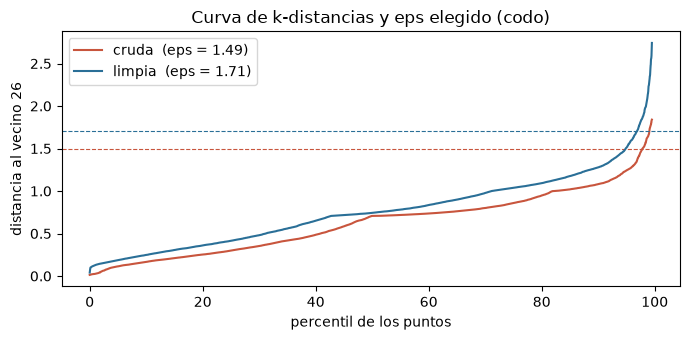

min_samples = 26 | eps = {'cruda': np.float64(1.494), 'limpia': np.float64(1.709)}


In [ ]:
MIN_SAMPLES = 2 * len(NUMERICAS + CATEGORICAS)


def elegir_eps(Z):
    vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z)
    distancias, _ = vecinos.kneighbors(Z[:10_000])
    k_distancias = np.sort(distancias[:, -1])
    k_distancias = k_distancias[: int(len(k_distancias) * 0.995)]
    codo = KneeLocator(range(len(k_distancias)), k_distancias, curve="convex", direction="increasing")
    return k_distancias[codo.knee], k_distancias


eps = {}
fig, ax = plt.subplots(figsize=(7, 3.5))
for escenario, color in [("cruda", "#c8553d"), ("limpia", "#2a6f97")]:
    eps[escenario], curva = elegir_eps(prep[escenario]["Z"])
    ax.plot(np.linspace(0, 99.5, len(curva)), curva, color=color, label=f"{escenario}  (eps = {eps[escenario]:.2f})")
    ax.axhline(eps[escenario], color=color, ls="--", lw=0.8)
ax.set_xlabel("percentil de los puntos")
ax.set_ylabel(f"distancia al vecino {MIN_SAMPLES}")
ax.set_title("Curva de k-distancias y eps elegido (codo)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURAS / "dbscan_k_distancias.png", dpi=130)
plt.show()
print("min_samples =", MIN_SAMPLES, "| eps =", {k: round(v, 3) for k, v in eps.items()})

## 2. Entrenar DBSCAN en las dos muestras

In [3]:
modelos_dbscan = {}
resumen = []
for escenario in ["cruda", "limpia"]:
    Z = prep[escenario]["Z"]
    modelo = DBSCAN(eps=eps[escenario], min_samples=MIN_SAMPLES, n_jobs=-1).fit(Z)
    modelos_dbscan[escenario] = modelo
    etiquetas = modelo.labels_
    resumen.append({
        "escenario": escenario,
        "eps": round(eps[escenario], 3),
        "clusters": etiquetas.max() + 1,
        "puntos núcleo": len(modelo.core_sample_indices_),
        "ruido (atípicos)": int((etiquetas == -1).sum()),
        "% ruido": round(100 * (etiquetas == -1).mean(), 2),
    })
pd.DataFrame(resumen)

,escenario,eps,clusters,puntos núcleo,ruido (atípicos),% ruido
0,cruda,1.494,4,49025,308,0.62
1,limpia,1.709,1,48444,730,1.46


In [ ]:
for escenario in ["cruda", "limpia"]:
    print(escenario, pd.Series(modelos_dbscan[escenario].labels_).value_counts().sort_index().to_dict())

cruda {-1: 308, 0: 4222, 1: 45248, 2: 189, 3: 33}
limpia {-1: 730, 0: 49270}


## 3. ¿Cómo son los contratos que DBSCAN marca como ruido? (muestra limpia)

In [5]:
datos = prep["limpia"]["datos"].copy()
datos["db_ruido"] = modelos_dbscan["limpia"].labels_ == -1
datos.groupby("db_ruido")[["valor_contrato", "plazo_dias", "adiciones_dias", "dias_firma_cargue"]].median()

,valor_contrato,plazo_dias,adiciones_dias,dias_firma_cargue
db_ruido,,,,
False,8400000.0,90.0,0.0,6.0
True,18486389.0,74.0,8.0,3.0


In [ ]:
tabla = pd.crosstab(datos["modalidad_de_contratacion"], datos["db_ruido"], normalize="columns") * 100
tabla.columns = ["% en normales", "% en ruido"]
tabla.sort_values("% en ruido", ascending=False).round(1).head(8)

,% en normales,% en ruido
modalidad_de_contratacion,,
REGIMEN ESPECIAL,37.6,46.7
CONTRATACION DIRECTA (LEY 1150 DE 2007),49.9,27.7
CONTRATACION MINIMA CUANTIA,8.8,10.0
SUBASTA,0.5,3.2
LICITACION PUBLICA,0.2,3.0
CONTRATOS Y CONVENIOS CON MAS DE DOS PARTES,1.1,3.0
CONCURSO DE MERITOS ABIERTO,0.4,2.9
SELECCION ABREVIADA DE MENOR CUANTIA (LEY 1150 DE 2007),1.3,2.2


## 4. Guardar resultados

* Las etiquetas de cada contrato de las muestras.
* Para el escenario limpio, los **puntos núcleo**: el notebook 05 los usa para clasificar los 5,6 millones de contratos.

In [7]:
for escenario in ["cruda", "limpia"]:
    etiquetas = modelos_dbscan[escenario].labels_
    pd.DataFrame({
        "row_id": prep[escenario]["datos"]["row_id"],
        "db_cluster": etiquetas,
        "db_ruido": etiquetas == -1,
    }).to_parquet(RESULTADOS / f"dbscan_{escenario}.parquet")

nucleos = modelos_dbscan["limpia"].core_sample_indices_
joblib.dump({
    "eps": eps["limpia"],
    "min_samples": MIN_SAMPLES,
    "Z_nucleos": prep["limpia"]["Z"][nucleos],
    "X_cat_nucleos": prep["limpia"]["X_cat"][nucleos],
    "cluster_nucleos": modelos_dbscan["limpia"].labels_[nucleos],
}, MODELOS / "dbscan_limpio.joblib")
print("Guardado")

Guardado
